# 3. Ingeniería de variables (Feature Engineering)

**Objetivo:** transformar los datos limpios en una matriz numérica lista para los modelos, creando variables nuevas a partir de lo aprendido en el EDA.

Variables nuevas:
| Variable | Idea |
|---|---|
| `FamilySize` | `SibSp + Parch + 1` |
| `IsAlone` | 1 si viaja solo |
| `FarePerPerson` | Tarifa repartida entre la familia/boleto |
| `IsChild` | 1 si tiene menos de 13 años |
| `AgeGroup` | Edad discretizada |
| `TicketGroupSize` | Cuántos pasajeros comparten el mismo boleto |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid", palette="Set2")
df = pd.read_csv("data/titanic_clean.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Title,Sex,Age,AgeWasMissing,SibSp,Parch,Ticket,Fare,Deck,HasCabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Mr,male,22.0,0,1,0,A/5 21171,7.2500,U,0,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,female,38.0,0,1,0,PC 17599,71.2833,C,1,C
2,3,1,3,"Heikkinen, Miss. Laina",Miss,female,26.0,0,0,0,STON/O2. 3101282,7.9250,U,0,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,female,35.0,0,1,0,113803,53.1000,C,1,S
4,5,0,3,"Allen, Mr. William Henry",Mr,male,35.0,0,0,0,373450,8.0500,U,0,S


## 3.1 Variables familiares y de boleto

In [2]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["TicketGroupSize"] = df.groupby("Ticket")["Ticket"].transform("count")
df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"]
df[["FamilySize", "IsAlone", "TicketGroupSize", "Fare", "FarePerPerson"]].describe().round(2)

,FamilySize,IsAlone,TicketGroupSize,Fare,FarePerPerson
count,891.00,891.00,891.00,891.00,891.00
mean,1.90,0.60,1.79,32.20,17.79
std,1.61,0.49,1.36,49.69,21.22
min,1.00,0.00,1.00,0.00,0.00
25%,1.00,0.00,1.00,7.91,7.76
50%,1.00,1.00,1.00,14.45,8.85
75%,2.00,1.00,2.00,31.00,24.29
max,11.00,1.00,7.00,512.33,221.78


## 3.2 Variables de edad

In [3]:
df["IsChild"] = (df["Age"] < 13).astype(int)
df["AgeGroup"] = pd.cut(df["Age"], bins=[-1, 12, 18, 35, 60, 120],
                        labels=["Nino", "Adolescente", "Joven", "Adulto", "Mayor"]).astype(str)
df.groupby("AgeGroup")["Survived"].mean().round(3)

AgeGroup
Adolescente    0.429
Adulto         0.398
Joven          0.353
Mayor          0.227
Nino           0.575
Name: Survived, dtype: float64

## 3.3 Transformación de tarifa (sesgo)

In [4]:
df["LogFare"] = np.log1p(df["Fare"])
print("Asimetría Fare:   ", round(df["Fare"].skew(), 2))
print("Asimetría LogFare:", round(df["LogFare"].skew(), 2))

Asimetría Fare:    4.79
Asimetría LogFare: 0.39


## 3.4 Codificación de variables categóricas

In [5]:
df["Sex"] = (df["Sex"] == "male").astype(int)   # 1 = hombre, 0 = mujer
df = df.rename(columns={"Sex": "Sex_male"})

categoricas = ["Embarked", "Title", "Deck", "AgeGroup"]
df = pd.get_dummies(df, columns=categoricas, drop_first=False, dtype=int)

# Columnas que no aportan como predictores directos
df = df.drop(columns=["PassengerId", "Name", "Ticket"])
print("Forma final:", df.shape)
df.head()

Forma final: (891, 36)


,Survived,Pclass,Sex_male,Age,AgeWasMissing,SibSp,Parch,Fare,HasCabin,FamilySize,...,Deck_D,Deck_E,Deck_F,Deck_G,Deck_U,AgeGroup_Adolescente,AgeGroup_Adulto,AgeGroup_Joven,AgeGroup_Mayor,AgeGroup_Nino
0,0,3,1,22.0,0,1,0,7.2500,0,2,...,0,0,0,0,1,0,0,1,0,0
1,1,1,0,38.0,0,1,0,71.2833,1,2,...,0,0,0,0,0,0,1,0,0,0
2,1,3,0,26.0,0,0,0,7.9250,0,1,...,0,0,0,0,1,0,0,1,0,0
3,1,1,0,35.0,0,1,0,53.1000,1,2,...,0,0,0,0,0,0,0,1,0,0
4,0,3,1,35.0,0,0,0,8.0500,0,1,...,0,0,0,0,1,0,0,1,0,0


## 3.5 Relevancia de las variables

In [6]:
X = df.drop(columns="Survived")
y = df["Survived"]

corr = X.corrwith(y).sort_values(key=abs, ascending=False)
mi = pd.Series(mutual_info_classif(X, y, random_state=42), index=X.columns).sort_values(ascending=False)

relevancia = pd.DataFrame({"correlacion": corr.round(3), "informacion_mutua": mi.round(3)}).sort_values("informacion_mutua", ascending=False)
relevancia.head(15)

,correlacion,informacion_mutua
Title_Mr,-0.549,0.160
Fare,0.257,0.143
Sex_male,-0.543,0.135
LogFare,0.330,0.127
FarePerPerson,0.255,0.101
Title_Miss,0.336,0.057
FamilySize,0.017,0.056
Pclass,-0.338,0.053
TicketGroupSize,0.038,0.053
Age,-0.079,0.046


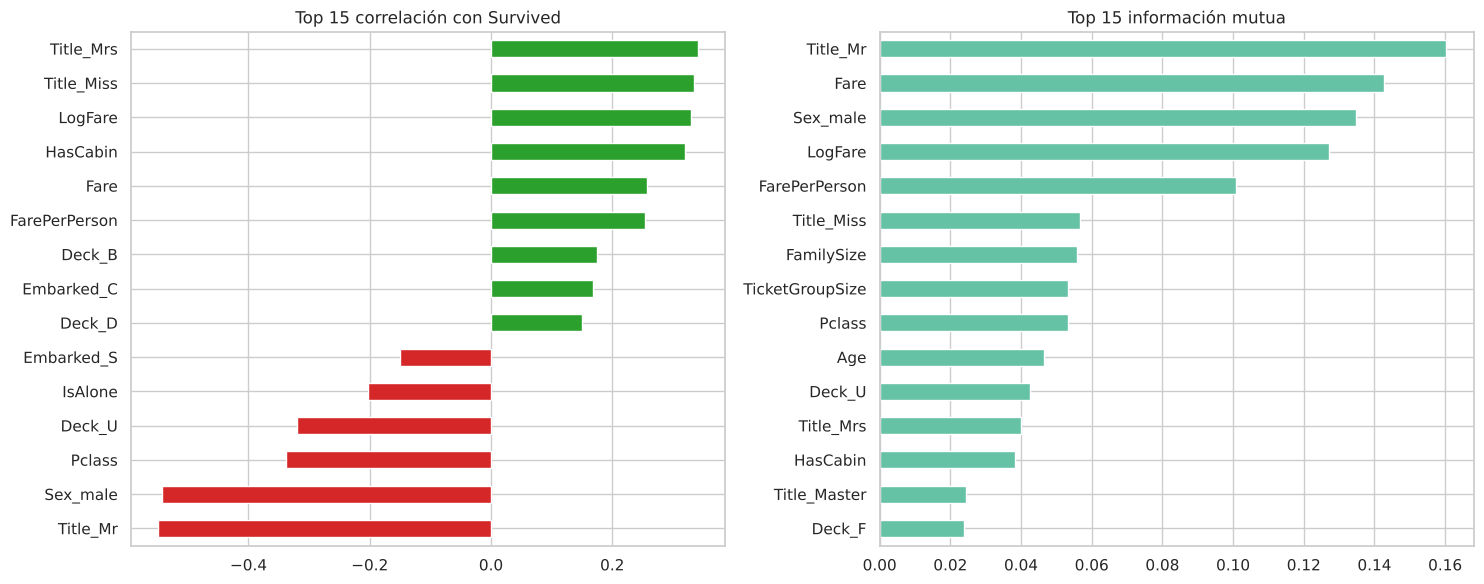

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
corr.head(15).sort_values().plot.barh(ax=axes[0], color=["#d62728" if v < 0 else "#2ca02c" for v in corr.head(15).sort_values()])
axes[0].set_title("Top 15 correlación con Survived")
mi.head(15).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Top 15 información mutua")
plt.tight_layout(); plt.show()

## 3.6 Multicolinealidad

In [8]:
matriz = X.corr().abs()
sup = matriz.where(np.triu(np.ones(matriz.shape), k=1).astype(bool))
pares = sup.stack().sort_values(ascending=False)
pares[pares > 0.8]

IsChild   AgeGroup_Nino    1.000000
HasCabin  Deck_U           1.000000
SibSp     FamilySize       0.890712
Sex_male  Title_Mr         0.867334
Fare      FarePerPerson    0.839037
dtype: float64

Hay pares muy correlacionados (por ejemplo `Sex_male` con `Title_Mr`, `Fare` con `LogFare`, `HasCabin` con `Deck_U`). Los modelos de árboles los toleran bien; para los lineales se usa regularización (la regresión logística de scikit-learn la trae por defecto). Los conservamos y dejamos que la comparación de modelos decida.

## 3.7 Guardar dataset de modelado

In [9]:
df.to_csv("data/titanic_features.csv", index=False)
print("Guardado data/titanic_features.csv ->", df.shape)
print("Predictores:", X.shape[1])

Guardado data/titanic_features.csv -> (891, 36)
Predictores: 35


## Resumen
- Se crearon 7 variables nuevas (`FamilySize`, `IsAlone`, `TicketGroupSize`, `FarePerPerson`, `IsChild`, `AgeGroup`, `LogFare`).
- Se codificaron las categóricas con *one-hot encoding*.
- Las variables más informativas son el sexo / título, la clase, la tarifa y la cabina, lo que coincide con el EDA.

**Siguiente paso:** `4_machine_learning.ipynb`.